### E-Commerce Review Intelligence System

**MBA Business Analytics Assignment**  
**Dataset:** Amazon Fine Food Reviews

This notebook develops an end-to-end review intelligence workflow that translates unstructured customer feedback into actionable product and customer-experience insights.

#### Business Problem

E-commerce leaders receive thousands of product reviews, but manually reading them does not scale. The business needs a reliable way to identify how customers feel, understand the themes behind that feedback, and prioritize products where negative experiences create the greatest commercial risk.

**Decision question:** Which products and customer-experience themes should management investigate first to protect customer satisfaction and future revenue?



#### Dataset Description

This analysis uses the **Amazon Fine Food Reviews dataset.** Each record contains a product identifier, a 1-5 star rating, a review summary, and the full review text. Ratings provide a practical sentiment proxy: scores 1-2 are negative, 3 is neutral, and 4-5 are positive.



| # | Column | Description |
|---:|---|---|
| 1 | `Id` | Unique row or review identifier |
| 2 | `ProductId` | Unique identifier for the food or gourmet product |
| 3 | `UserId` | Unique identifier for the reviewer |
| 4 | `ProfileName` | Name or nickname of the reviewer |
| 5 | `HelpfulnessNumerator` | Number of users who found the review helpful |
| 6 | `HelpfulnessDenominator` | Total number of votes on whether the review was helpful |
| 7 | `Score` | Star rating from 1 to 5 |
| 8 | `Time` | Timestamp of the review |
| 9 | `Summary` | Short text summary or title of the review |
| 10 | `Text` | Full text content of the customer review |

In [1]:
# Experiment 1                 Experiment 2                 Experiment 3

# TF-IDF                       Word Embeddings              Pretrained DistilBERT
#    ↓                              ↓                              ↓
# Logistic Regression             LSTM                       Self-Attention
#    ↓                              ↓                              ↓
# Sentiment                     Sentiment                       Sentiment

# Statistical NLP             Sequential Deep Learning      Transformer NLP

In [2]:
# `Experiment 1`
# "The food is not very good"
#         ↓ TF-IDF
# Large sparse vector
#         ↓
# Logistic Regression
#         ↓
# Predicted Sentiment

#  ---------------------------------------------------------

# `Experiment 2`
# "The food is not very good"
#        ↓ Word tokenizer
# [15, 83, 9, 37, 24, 51]
#        ↓ Embedding
# Dense word vectors
#        ↓ LSTM
# Sequential representation
#        ↓ Dense + Softmax
# Predicted Sentiment
# Negative / Neutral / Positive

#  ---------------------------------------------------------


In [3]:
# `Experiment 3`
# "The food is not very good"
#            ↓
# DistilBERT Tokenizer
#            ↓
# Subword Tokens
# + Attention Mask
#            ↓
# Pretrained DistilBERT
#    Transformer Layers
#            ↓
# Self-Attention
#            ↓
# Contextual Representation
#            ↓
# Classification Head
#            ↓
# Negative / Neutral / Positive

#  ---------------------------------------------------------

In [4]:
#                     RAW REVIEWS
#                          │
#                          ▼
#               ┌────────────────────┐
#               │ Exploratory Data   │
#               │ Analysis           │
#               └─────────┬──────────┘
#                         │
#                         ▼
#              Cleaning + Label Creation
#                         │
#               ┌─────────┴──────────┐
#               │                    │
#               ▼                    ▼
#       CLASSICAL NLP           TRANSFORMER
#               │                    │
#         TF-IDF / LSTM          Tokenizer
#           ┌───┴───┐                │
#           ▼       ▼                ▼
#      Logistic                     DistilBERT
#      Regression                     │
#           │       │                 │
#           └───────┴────────┬────────┘
#                            ▼
#                    MODEL EVALUATION
#                            │
#       ┌────────────────────┼──────────────────┐
#       ▼                    ▼                  ▼
#    Accuracy             Macro F1        Confusion Matrix
#                            │
#                            ▼
#                      ERROR ANALYSIS
#                            │
#                            ▼
#                       BEST MODEL
#                            │
#                            ▼
#                        BERTopic
#                            │
#                            ▼
#                 TOPIC × SENTIMENT
#                            │
#                            ▼
#                    BUSINESS INSIGHTS
#                            │
#                ┌───────────┼────────────┐
#                ▼           ▼            ▼
#              Product     Marketing     Service
#            Improvement    Insights    Improvement

1. Importing Libraries

In [5]:
!python3 -m pip install torch transformers datasets accelerate scikit-learn pandas numpy matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable


In [6]:
%pip install "numpy<2"

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [7]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import os
import random

import torch


In [8]:

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [9]:
from datasets import Dataset

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback,
    DataCollatorWithPadding
)

/Users/shubhamkumar/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
/Users/shubhamkumar/Library/Python/3.9/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [10]:
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print("Device: ", device)

Device:  cpu


In [11]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

2. Importing Datasets

In [12]:
df = pd.read_csv("./Reviews.csv")

In [13]:
rows, cols = df.shape
print(f"Rows: {rows}, Columns: {cols}")


Rows: 568454, Columns: 10


3. Examining Dataset

In [14]:
df.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [15]:
df.columns.tolist()

['Id',
 'ProductId',
 'UserId',
 'ProfileName',
 'HelpfulnessNumerator',
 'HelpfulnessDenominator',
 'Score',
 'Time',
 'Summary',
 'Text']

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 568454 entries, 0 to 568453
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   Id                      568454 non-null  int64 
 1   ProductId               568454 non-null  object
 2   UserId                  568454 non-null  object
 3   ProfileName             568428 non-null  object
 4   HelpfulnessNumerator    568454 non-null  int64 
 5   HelpfulnessDenominator  568454 non-null  int64 
 6   Score                   568454 non-null  int64 
 7   Time                    568454 non-null  int64 
 8   Summary                 568427 non-null  object
 9   Text                    568454 non-null  object
dtypes: int64(5), object(5)
memory usage: 43.4+ MB


Missing Values

In [17]:
df.isnull().sum()

Id                         0
ProductId                  0
UserId                     0
ProfileName               26
HelpfulnessNumerator       0
HelpfulnessDenominator     0
Score                      0
Time                       0
Summary                   27
Text                       0
dtype: int64

In [18]:
df = df.dropna(subset=["Summary"])
df = df.reset_index(drop=True)

In [19]:
print("Total duplicated rows in the dataframe:", df.duplicated().sum())

Total duplicated rows in the dataframe: 0


In [20]:
df["Score"].value_counts().sort_index()

Score
1     52268
2     29744
3     42638
4     80655
5    363122
Name: count, dtype: int64

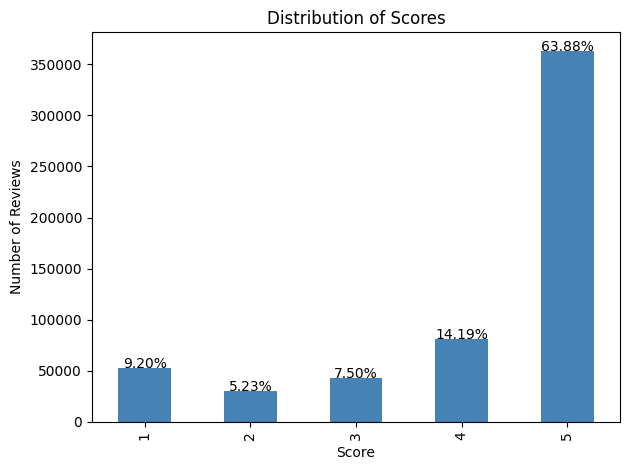

In [21]:
# Plot the distribution of review scores
df["Score"].value_counts().sort_index().plot(
    kind="bar",
    color="steelblue",
)

# Show percentage on the bars
total = len(df["Score"])
for p in plt.gca().patches:
    height = p.get_height()
    plt.gca().text(
        p.get_x() + p.get_width() / 2.,
        height,
        '{:.2f}%'.format(100 * height / total),
        ha="center"
    )

plt.title("Distribution of Scores")
plt.xlabel("Score")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

4. Convert Rating into Sentiment
* [1, 2] -> Negative
* [ 3  ]    -> Neutral
* [4, 5] -> Positive

In [22]:
def create_sentiment(score: int) -> str:
    if score <= 2:
        return "Negative"
    elif score == 3:
        return "Neutral"
    else:
        return "Positive"

In [23]:
df["Sentiment"] = df["Score"].apply(create_sentiment)

In [24]:
df[["Score", "Sentiment"]].head(10)

,Score,Sentiment
0,5,Positive
1,1,Negative
2,4,Positive
3,2,Negative
4,5,Positive
5,4,Positive
6,5,Positive
7,5,Positive
8,5,Positive
9,5,Positive


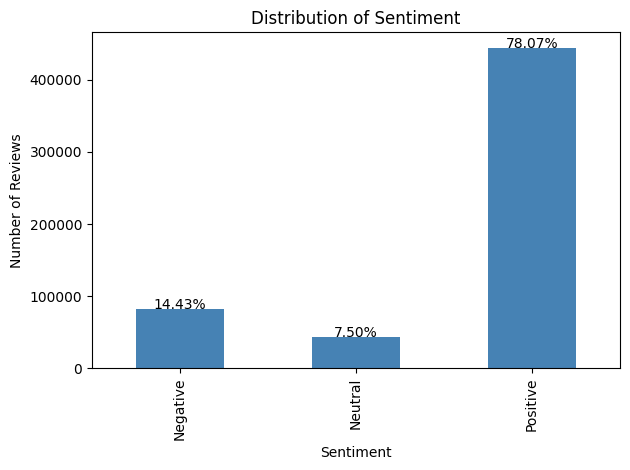

In [25]:
# Plot the distribution of Sentiment
df["Sentiment"].value_counts().sort_index().plot(
    kind="bar",
    color="steelblue",
)

# Show percentage on the bars
total = len(df["Sentiment"])
for p in plt.gca().patches:
    height = p.get_height()
    plt.gca().text(
        p.get_x() + p.get_width() / 2.,
        height,
        '{:.2f}%'.format(100 * height / total),
        ha="center"
    )


plt.title("Distribution of Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

Inference: Class Highly Imbalanced -
* Positive - 78 %
* Neutral - 7.5%
* Negative - 14.5 %

Merging Summary with Text in Review Column appended by comma(',')

In [26]:
df["Review"] = (df["Summary"].fillna("") + " , " + df["Text"].fillna(""))
df["Review"].head()

0    Good Quality Dog Food , I have bought several ...
1    Not as Advertised , Product arrived labeled as...
2    "Delight" says it all , This is a confection t...
3    Cough Medicine , If you are looking for the se...
4    Great taffy , Great taffy at a great price.  T...
Name: Review, dtype: object

5. Basic Text Preprocessing

In [27]:
import re

In [28]:
def clean_text_transformer(text: str) -> str:
    text = str(text)

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Normalize repeated whitespaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


In [29]:
df["Review"] = df["Review"].apply(clean_text_transformer)

* Inference : Stopwords should not be removed as it will remove the sentiment in the review comments

In [30]:
# TensorFlow works more naturally with numeric classes.
label_map = {
    "Negative": 0,
    "Neutral": 1,
    "Positive": 2
}

In [31]:
df["label"] = df["Sentiment"].map(label_map)

In [32]:
df[["Sentiment", "label"]].head()

,Sentiment,label
0,Positive,2
1,Negative,0
2,Positive,2
3,Negative,0
4,Positive,2


In [33]:
id2label = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

label2id = {
    "Negative": 0,
    "Neutral": 1,
    "Positive": 2
}

6. Train / Validation / Test Split

* 70% training
* 15% validation
* 15% testing

Experiment 3: Transformer

In [34]:
# Keep a small, balanced sample for quick CPU experiments
SAMPLES_PER_CLASS = 20

df = (
    df.groupby("label", group_keys=False)
      .apply(
          lambda group: group.sample(
              n=min(len(group), SAMPLES_PER_CLASS),
              random_state=42
          )
    )
    .reset_index(drop=True)
)

print("Trimmed dataset size:", len(df))
print(df["label"].value_counts())

Trimmed dataset size: 60
label
0    20
1    20
2    20
Name: count, dtype: int64


/var/folders/x5/p4zw4lnd4hg4fvf7r_ppczlm0000gn/T/ipykernel_17371/4160159322.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df.groupby("label", group_keys=False)


In [35]:
train_df, temp_df = train_test_split(
    df[["Review", "label"]],
    test_size=0.3,
    random_state=SEED,
    stratify=df["label"]
)

In [36]:
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=SEED,
    stratify=temp_df["label"]
)

In [37]:
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

In [38]:
print("Training set size:", len(train_df))
print("Validation set size:", len(val_df))
print("Test set size:", len(test_df))

Training set size: 42
Validation set size: 9
Test set size: 9


#### 7. Choosing DistilBERT as Transformer Model

In [39]:
!python3 -c 'from huggingface_hub import snapshot_download; models=["distilbert-base-uncased"]; [print(f"Downloading {m}...") or snapshot_download(repo_id=m) for m in models]; print("Downloads complete.")'

/Users/shubhamkumar/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
Fetching 12 files: 100%|█████████████████████| 12/12 [00:00<00:00, 1975.34it/s]
Downloads complete.


In [40]:
MODEL_NAME = "distilbert-base-uncased"

### Tokenization 
> Tokenizer learns Vocabulary

> Sample Tokenization Process

In [41]:
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

OOV = Out Of Vocabulary.

In [42]:
sample_text = train_df["Review"].iloc[2]
print(sample_text)

took a gamble on this product.. and lost.... , i was wondering why it was so much cheaper than the other flavors... now I know... my cat wouldnt touch it. He acted like it stunk and backed away. he then went over to eat his day old dried cat food rather than eat this junk. Im concerned that someone wrote it might be tainted and be recalled later. well ill save it in case it does get recalled-maybe then i can get a refund. i dont like how amazon wont let you return food items(unless recalled), especially when they are just unopened cans. alot of people gave it good ratings but alot of people didnt.. I think if you only have one cat like me, the odds are bad... and you shouldnt buy it.


In [43]:
tokens = tokenizer.tokenize(sample_text)
print(tokens)

['took', 'a', 'gamble', 'on', 'this', 'product', '.', '.', 'and', 'lost', '.', '.', '.', '.', ',', 'i', 'was', 'wondering', 'why', 'it', 'was', 'so', 'much', 'cheaper', 'than', 'the', 'other', 'flavors', '.', '.', '.', 'now', 'i', 'know', '.', '.', '.', 'my', 'cat', 'wouldn', '##t', 'touch', 'it', '.', 'he', 'acted', 'like', 'it', 'stu', '##nk', 'and', 'backed', 'away', '.', 'he', 'then', 'went', 'over', 'to', 'eat', 'his', 'day', 'old', 'dried', 'cat', 'food', 'rather', 'than', 'eat', 'this', 'junk', '.', 'im', 'concerned', 'that', 'someone', 'wrote', 'it', 'might', 'be', 'tainted', 'and', 'be', 'recalled', 'later', '.', 'well', 'ill', 'save', 'it', 'in', 'case', 'it', 'does', 'get', 'recalled', '-', 'maybe', 'then', 'i', 'can', 'get', 'a', 'ref', '##und', '.', 'i', 'don', '##t', 'like', 'how', 'amazon', 'won', '##t', 'let', 'you', 'return', 'food', 'items', '(', 'unless', 'recalled', ')', ',', 'especially', 'when', 'they', 'are', 'just', 'uno', '##pen', '##ed', 'cans', '.', 'al', '##

In [44]:
encoded = tokenizer(
    sample_text,
    truncation=True,
    max_length=256
)

In [45]:
print(encoded["input_ids"])

[101, 2165, 1037, 18503, 2006, 2023, 4031, 1012, 1012, 1998, 2439, 1012, 1012, 1012, 1012, 1010, 1045, 2001, 6603, 2339, 2009, 2001, 2061, 2172, 16269, 2084, 1996, 2060, 26389, 1012, 1012, 1012, 2085, 1045, 2113, 1012, 1012, 1012, 2026, 4937, 2876, 2102, 3543, 2009, 1012, 2002, 6051, 2066, 2009, 24646, 8950, 1998, 6153, 2185, 1012, 2002, 2059, 2253, 2058, 2000, 4521, 2010, 2154, 2214, 9550, 4937, 2833, 2738, 2084, 4521, 2023, 18015, 1012, 10047, 4986, 2008, 2619, 2626, 2009, 2453, 2022, 26392, 1998, 2022, 7383, 2101, 1012, 2092, 5665, 3828, 2009, 1999, 2553, 2009, 2515, 2131, 7383, 1011, 2672, 2059, 1045, 2064, 2131, 1037, 25416, 8630, 1012, 1045, 2123, 2102, 2066, 2129, 9733, 2180, 2102, 2292, 2017, 2709, 2833, 5167, 1006, 4983, 7383, 1007, 1010, 2926, 2043, 2027, 2024, 2074, 27776, 11837, 2098, 18484, 1012, 2632, 4140, 1997, 2111, 2435, 2009, 2204, 8599, 2021, 2632, 4140, 1997, 2111, 2134, 2102, 1012, 1012, 1045, 2228, 2065, 2017, 2069, 2031, 2028, 4937, 2066, 2033, 1010, 1996, 10238

Each tokenizer token corresponds to a vocabulary ID.

In [46]:
print(encoded["attention_mask"])

[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


The attention mask tells the model which positions contain actual sequence tokens versus padding:
> 1 → real token position

> 0 → padding position

#### Tokenization Length Calculation 

In [47]:
token_lengths = train_df["Review"].apply(
    lambda x: len(
        tokenizer.encode(
            x,
            add_special_tokens=True,
            truncation=False
        )
    )
)

Token indices sequence length is longer than the specified maximum sequence length for this model (631 > 512). Running this sequence through the model will result in indexing errors


In [48]:
token_lengths.describe(
    percentiles=[
        0.50,
        0.75,
        0.90,
        0.95,
        0.99
    ]
)

count     42.000000
mean     126.666667
std      114.713358
min       31.000000
50%       97.500000
75%      142.750000
90%      222.300000
95%      266.550000
99%      573.600000
max      631.000000
Name: Review, dtype: float64

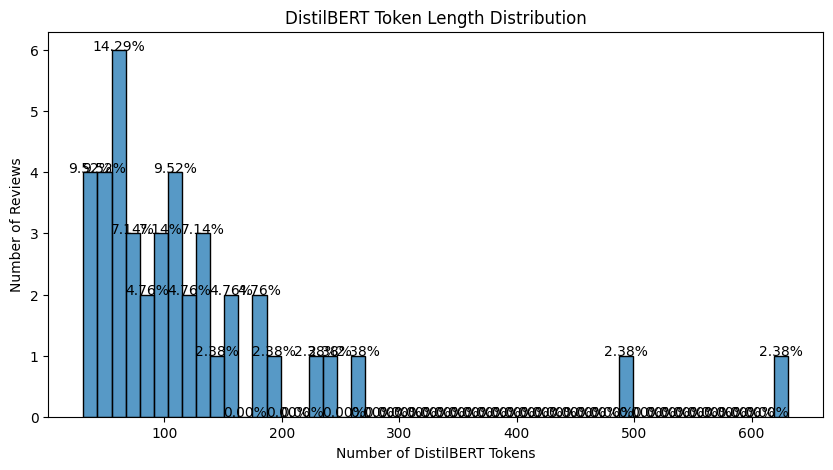

In [49]:
plt.figure(figsize=(10, 5))

sns.histplot(
    token_lengths,
    bins=50
)

# Show percentage on the bars
total = len(token_lengths)
for p in plt.gca().patches:
    height = p.get_height()
    plt.gca().text(
        p.get_x() + p.get_width() / 2.,
        height,
        '{:.2f}%'.format(100 * height / total),
        ha="center"
    )

plt.xlabel("Number of DistilBERT Tokens")
plt.ylabel("Number of Reviews")
plt.title(
    "DistilBERT Token Length Distribution"
)

plt.show()

In [50]:
MAX_LENGTH = 256

Convert DataFrames into Hugging Face Datasets

In [51]:
train_dataset = Dataset.from_pandas(train_df)

val_dataset = Dataset.from_pandas(val_df)

test_dataset = Dataset.from_pandas(test_df)

In [52]:
train_dataset

Dataset({
    features: ['Review', 'label'],
    num_rows: 42
})

Creating Tokenizer Function

In [53]:
def tokenize_function(batch):
    return tokenizer(
        batch["Review"],
        truncation=True,
        max_length=MAX_LENGTH
    )

Tokenize all Splits

In [54]:
train_tokenized = train_dataset.map(tokenize_function, batched=True)
val_tokenized = val_dataset.map(tokenize_function, batched=True)
test_tokenized = test_dataset.map(tokenize_function, batched=True)

Map: 100%|██████████| 9/9 [00:00<00:00, 1013.50 examples/s]


In [55]:
print(train_tokenized[0])

{'Review': "Discovered in Munich , I once ordered an entire pot of coffee at a cafe in Munich. I was studying abroad in Europe and was in Munich for the weekend. I had the morning and decided to take it easy. There's nothing better than spending a morning outdoors in early spring in a cafe, watching the world go by, with a newspaper or three. In Europe, they never rush you along in a cafe. Anyways, the coffee they served was Dallmayr. I was hooked from that day on. I coworker recently brought a bag of Jacobs for the breakroom coffee maker. It's his favorite. I told him Dallmayr's better. Now, thanks to Amazon, I have a chance to prove it. Maybe I'll convince him, maybe not, but now I know where to find this lovely coffee regardless. :)", 'label': 2, 'input_ids': [101, 3603, 1999, 7469, 1010, 1045, 2320, 3641, 2019, 2972, 8962, 1997, 4157, 2012, 1037, 7668, 1999, 7469, 1012, 1045, 2001, 5702, 6917, 1999, 2885, 1998, 2001, 1999, 7469, 2005, 1996, 5353, 1012, 1045, 2018, 1996, 2851, 1998,

#### Dynamic Padding -
dynamic padding pads each batch only to the longest sequence within that batch.

In [56]:
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

Load Pretrained DistilBERT

In [57]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


#### Define Evaluation Metrics

In [58]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    accuracy = accuracy_score(labels, predictions)

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            labels,
            predictions,
            average='macro',
            zero_division=0
        )
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "macro_f1": f1
    }

#### Training Model

In [59]:
training_args = TrainingArguments(
    output_dir='./distilbert_sentiment',
    learning_rate=2e-5, # lower bcoz we're fine-tuning pretrained weights.

    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,

    num_train_epochs=3,

    weight_decay=0.01, # adds regularization to reduce overfitting.

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,

    metric_for_best_model="macro_f1",
    greater_is_better=True,

    logging_steps=100,

    save_total_limit=2
)

In [60]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=val_tokenized,
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=2
        )
    ]
)

/var/folders/x5/p4zw4lnd4hg4fvf7r_ppczlm0000gn/T/ipykernel_17371/2998161210.py:1: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


In [61]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,Macro F1
1,No log,1.098546,0.333333,0.111111,0.333333,0.166667
2,No log,1.094027,0.222222,0.083333,0.222222,0.121212
3,No log,1.092579,0.222222,0.111111,0.222222,0.148148


TrainOutput(global_step=9, training_loss=1.0855688518948026, metrics={'train_runtime': 186.213, 'train_samples_per_second': 0.677, 'train_steps_per_second': 0.048, 'total_flos': 7716363579648.0, 'train_loss': 1.0855688518948026, 'epoch': 3.0})

#### Evaluate on Validation data

In [62]:
val_results = trainer.evaluate(
    val_tokenized
)

print(val_results)

{'eval_loss': 1.098546028137207, 'eval_accuracy': 0.3333333333333333, 'eval_precision': 0.1111111111111111, 'eval_recall': 0.3333333333333333, 'eval_macro_f1': 0.16666666666666666, 'eval_runtime': 2.7599, 'eval_samples_per_second': 3.261, 'eval_steps_per_second': 0.362, 'epoch': 3.0}


In [63]:
test_results = trainer.evaluate(
    test_tokenized
)

print(test_results)

{'eval_loss': 1.104353427886963, 'eval_accuracy': 0.3333333333333333, 'eval_precision': 0.1111111111111111, 'eval_recall': 0.3333333333333333, 'eval_macro_f1': 0.16666666666666666, 'eval_runtime': 2.8294, 'eval_samples_per_second': 3.181, 'eval_steps_per_second': 0.353, 'epoch': 3.0}


In [64]:
pred_output = trainer.predict(
    test_tokenized
)

In [65]:
test_logits = pred_output.predictions

Visualise Accuracy

In [66]:
y_pred = np.argmax(
    test_logits,
    axis=1
)

Model Evaluation

In [67]:
y_test = test_df["label"].values

In [68]:
target_names = [
    "Negative",
    "Neutral",
    "Positive"
]


Classification Report

In [69]:
print(classification_report(
    y_test,
    y_pred,
    target_names=target_names,
    digits=4,
))

              precision    recall  f1-score   support

    Negative     0.0000    0.0000    0.0000         3
     Neutral     0.0000    0.0000    0.0000         3
    Positive     0.3333    1.0000    0.5000         3

    accuracy                         0.3333         9
   macro avg     0.1111    0.3333    0.1667         9
weighted avg     0.1111    0.3333    0.1667         9



/Users/shubhamkumar/Library/Python/3.9/lib/python/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/shubhamkumar/Library/Python/3.9/lib/python/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/shubhamkumar/Library/Python/3.9/lib/python/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitaliz

Confusion Matrix

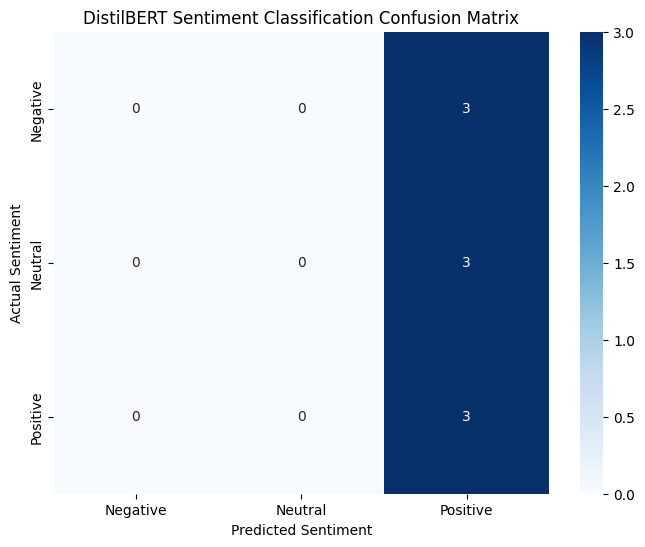

In [70]:
cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=target_names,
    yticklabels=target_names
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("DistilBERT Sentiment Classification Confusion Matrix")

plt.show()

Convert Logits to Probabilities

In [71]:
probabilities = torch.softmax(
    torch.tensor(test_logits),
    dim=1
).numpy()

In [72]:
probabilities[0]

array([0.3306395 , 0.30881286, 0.36054766], dtype=float32)

#### Error Analysis

In [73]:
results = pd.DataFrame({
    "Review": test_df["Review"].values,
    "Actual": y_test,
    "Predicted": y_pred,
    "Confidence": probabilities.max(axis=1)
})

In [74]:
results["Actual"] = (
    results["Actual"]
    .map(id2label)
)

results["Predicted"] = (
    results["Predicted"]
    .map(id2label)
)

In [75]:
error = results[
    results["Actual"] != results["Predicted"]
]

In [76]:
error.sort_values(
    by="Confidence",
    ascending=False
).head(20)

,Review,Actual,Predicted,Confidence
5,"Not my favorite! , I do not like the consistan...",Neutral,Positive,0.365848
1,"way to over priced , this bag was the size of ...",Negative,Positive,0.364930
6,"not as good as the regular ramen , Maruchan Li...",Neutral,Positive,0.361068
8,"Worst of all Timothy's K cups , I have tried a...",Negative,Positive,0.360908
0,"Bitter Brew , I liked the packaging and the id...",Neutral,Positive,0.360548
4,Very Dissappointed wtih recent Wellness compan...,Negative,Positive,0.348548


Running Test on Sample Sentences

In [77]:
def predict_sentiment(text):

    text = clean_text_transformer(text)

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH,
        padding=True
    )

    model_device = next(
        model.parameters()
    ).device

    inputs = {
        key: value.to(model_device)
        for key, value in inputs.items()
    }

    model.eval()

    with torch.no_grad():

        output = model(
            **inputs
        )

    probs = torch.softmax(
        output.logits,
        dim=1
    )[0]

    predicted_id = int(
        torch.argmax(probs)
    )

    return {
        "sentiment":
            id2label[predicted_id],

        "confidence":
            float(probs[predicted_id]),

        "probabilities": {
            id2label[i]: float(probs[i])
            for i in range(3)
        }
    }

In [78]:
predict_sentiment(
    "Excellent product and very fast delivery"
)

{'sentiment': 'Positive',
 'confidence': 0.3475985825061798,
 'probabilities': {'Negative': 0.3336739242076874,
  'Neutral': 0.3187274932861328,
  'Positive': 0.3475985825061798}}

In [79]:
predict_sentiment(
    "Absolutely awful quality and I would never buy this again"
)

{'sentiment': 'Positive',
 'confidence': 0.35050052404403687,
 'probabilities': {'Negative': 0.33212515711784363,
  'Neutral': 0.3173743486404419,
  'Positive': 0.35050052404403687}}

In [80]:
predict_sentiment(
    "The food tastes amazing but the package arrived damaged and late"
)

{'sentiment': 'Positive',
 'confidence': 0.3572235107421875,
 'probabilities': {'Negative': 0.3213323652744293,
  'Neutral': 0.3214441239833832,
  'Positive': 0.3572235107421875}}

Saving the Model

In [81]:
trainer.save_model("./final_distilbert_sentiment")

In [82]:
tokenizer.save_pretrained("./final_distilbert_sentiment")

('./final_distilbert_sentiment/tokenizer_config.json',
 './final_distilbert_sentiment/special_tokens_map.json',
 './final_distilbert_sentiment/vocab.txt',
 './final_distilbert_sentiment/added_tokens.json',
 './final_distilbert_sentiment/tokenizer.json')

In [84]:
experiment_3_results = {
    "Model":
        "Fine-tuned DistilBERT",

    "Accuracy":
        test_results["eval_accuracy"],

    "Macro Precision":
        test_results["eval_precision"],

    "Macro Recall":
        test_results["eval_recall"],

    "Macro F1":
        test_results["eval_macro_f1"]
}

experiment_3_results

{'Model': 'Fine-tuned DistilBERT',
 'Accuracy': 0.3333333333333333,
 'Macro Precision': 0.1111111111111111,
 'Macro Recall': 0.3333333333333333,
 'Macro F1': 0.16666666666666666}